# MX080 / M6: CP2 and control episode review

## Summary
Pressure/state evidence supports repeated control interventions and distinct operating levels. The 7–8 September high-CP2 plateau is abnormal relative to the preceding supported run. Filling and leak hypotheses are not confirmed by telemetry. The same observed equalization shape also occurs with Status_6=Off / Valve=0 and no recorded module control change.

This is a read-only diagnostic, not a retrained or activated model.

## Context & Methods

- Machine MX080, Module6 (assumed continuation of the displayed M6 case). CP2 HP/LP are primary; CP1, temperature and control tags are context.
- 20 Aug–12 Sep inclusive, source naive times interpreted as Asia/Bangkok. 24 source days; 10 raw focal days reread and source-SHA checked.
- Canonical dynamic ZIP receipts control source identity; saved minute Parquet hashes checked. The canonical corpus is not an exact SQL snapshot.
- Minute figures show observed averages with failed-quality minutes blank; raw figures omit ambiguous duplicate seconds and never interpolate.
- Matched run comparison: quality + stable control + Run + Status_6 On + Busy0 + SVOff. This is comparability, not verified health.
- Status_6 denotes valve control, not independent motor feedback. Pressure equality during Off is not certified recovery or proof of charging.
- Working 180–230 psi field band is descriptive and not a validated detector threshold. No charge amount, leak test, load/target recipe, suction/liquid temperature or current service record is available.
- Date windows were selected after inspection; all comparisons are retrospective, not prospective accuracy.
- Recompute: `python -m notebooks.support.mx080_m6_episode_review`, then `--raw`, then `--deliver`; no SQL reads/writes or training are performed. Artifacts require the private raw ZIPs and frozen Fleet study outputs.

In [1]:
from pathlib import Path
import json,pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
assert (ROOT/'README_System.md').exists(), 'Run from OPERATION_P root'
OUT=ROOT/'notebooks/outputs/mx080_m6_episode_review_20261005'
summary=json.loads((OUT/'summary.json').read_text(encoding='utf-8'))
display(pd.Series({k:summary[k] for k in ['source_period','source_files','raw_focal_files','raw_rows_reread','observed_module_minutes','quality_minutes','raw_minute_checks']}))

source_period              [2026-08-20, 2026-09-13]
source_files                                     24
raw_focal_files                                  10
raw_rows_reread                              851177
observed_module_minutes                       34550
quality_minutes                               34367
raw_minute_checks                                30
dtype: object

## Results

### 1. Compare operating levels
Medians use complete supported minutes only. Quantiles and full per-day states are available in daily.json and period_peer_comparison.json.

In [2]:
display(pd.DataFrame(summary['comparison_blocks']).round(2))
display(pd.Series(summary['cp2_percent_change'],name='7–8 Sep vs 3–7 Sep pre-intervention: percent change'))

,period,start,end,qualified_minutes,hp2_median,lp2_median,dp2_median,valve_median
0,pre_Aug23,2026-08-22,2026-08-23 15:00,2286,185.91,17.94,167.95,94.0
1,after_Aug26,2026-08-27,2026-08-31 15:59,6530,189.80,18.21,171.54,94.0
2,after_Sep2,2026-09-03,2026-09-07 08:00,6135,190.54,18.82,171.72,94.0
3,persistent_Sep7_8,2026-09-07 12:30,2026-09-08 23:50,2089,334.86,27.06,308.48,94.0
4,after_Sep12,2026-09-12 04:00,2026-09-13,1200,178.42,14.78,163.65,100.0


hp2    75.74
lp2    43.82
dp2    79.64
Name: 7–8 Sep vs 3–7 Sep pre-intervention: percent change, dtype: float64

### 2. Follow the repeated pressure trajectory
Grey marks Status_6=Off, not an independent compressor motor shutdown. HP/LP convergence alone does not establish refrigerant filling.
Recovery proposals: 27–30 Aug and 3–6 Sep require normal-operation review; 12 Sep has Valve100 and a different HP/LP level and needs a separate post-intervention review.

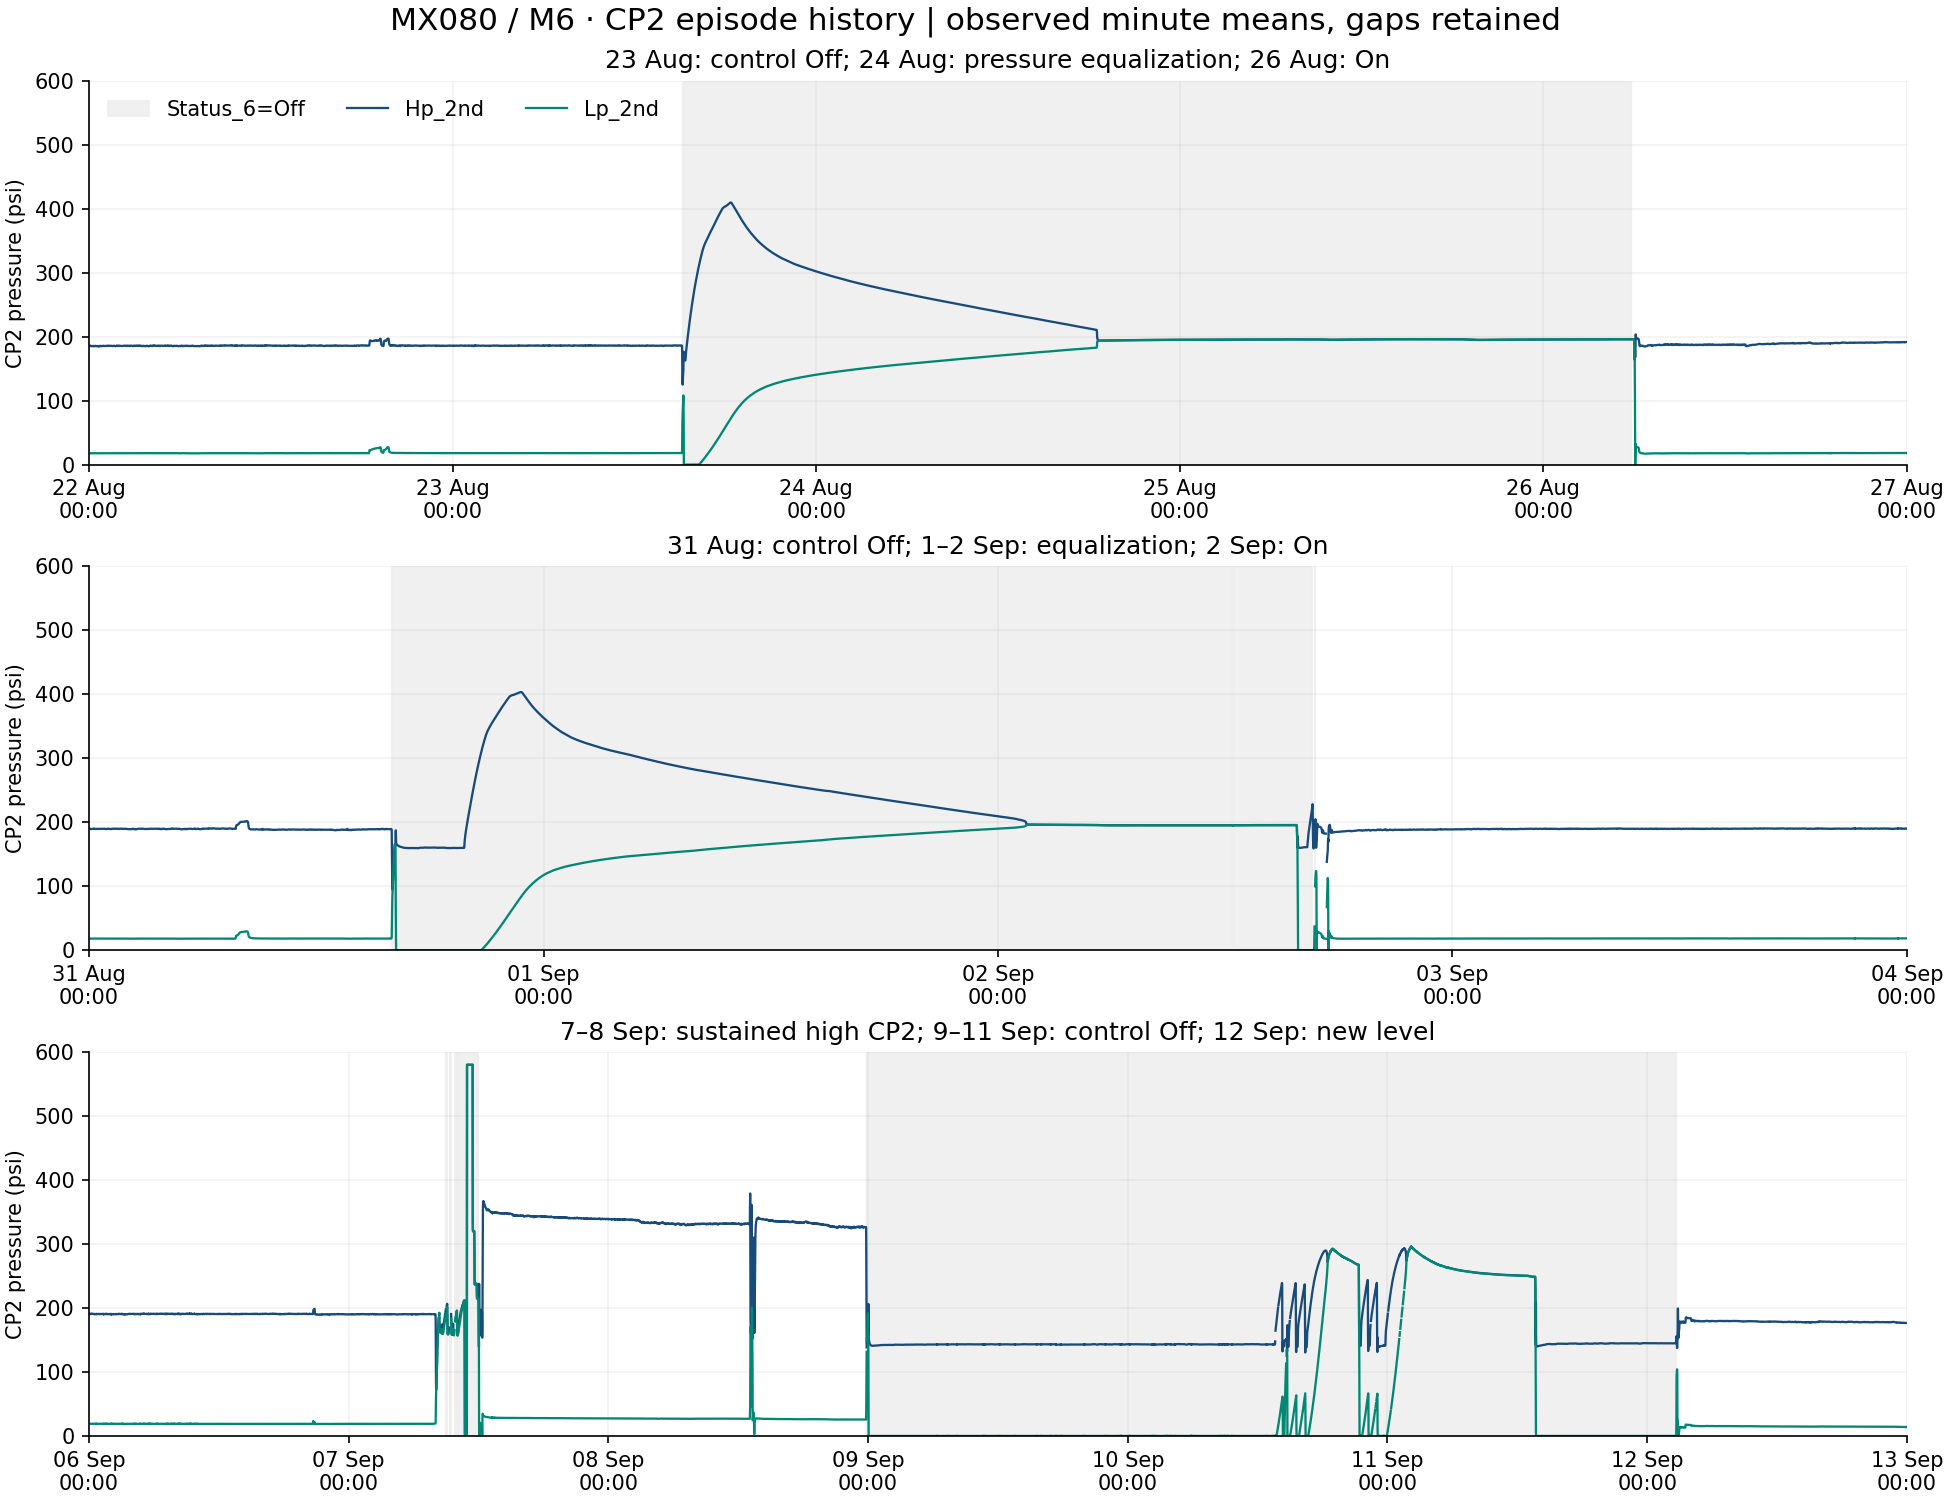

In [3]:
display(Image(filename=str(OUT/'cp2_episode_history.png')))

### 3. Inspect 7 September at original-second grain
07:00–08:00 remains near HP190/LP19. First observed HP outside the working180–230 band is08:02:47. Run→Stop is08:06:22, first ChangeValve08:09:14. From10:55:59–11:28:01, all four M6 pressure channels simultaneously read580.2 and both temperatures-200 (1896 observed rows). Other modules differ in the11:05 source snapshot. This strongly suggests an M6 acquisition/default-value issue, not a physical580psi charging trajectory. Older parsed messages contain DAQ failures and a later11:58:18 reboot; they are secondary context and do not prove the hardware cause. Sustained high differential after restart is a separate, supported-state signal. Keep the rail interval visible and quarantined for reference admission; current finite-number quality checks alone do not detect it.

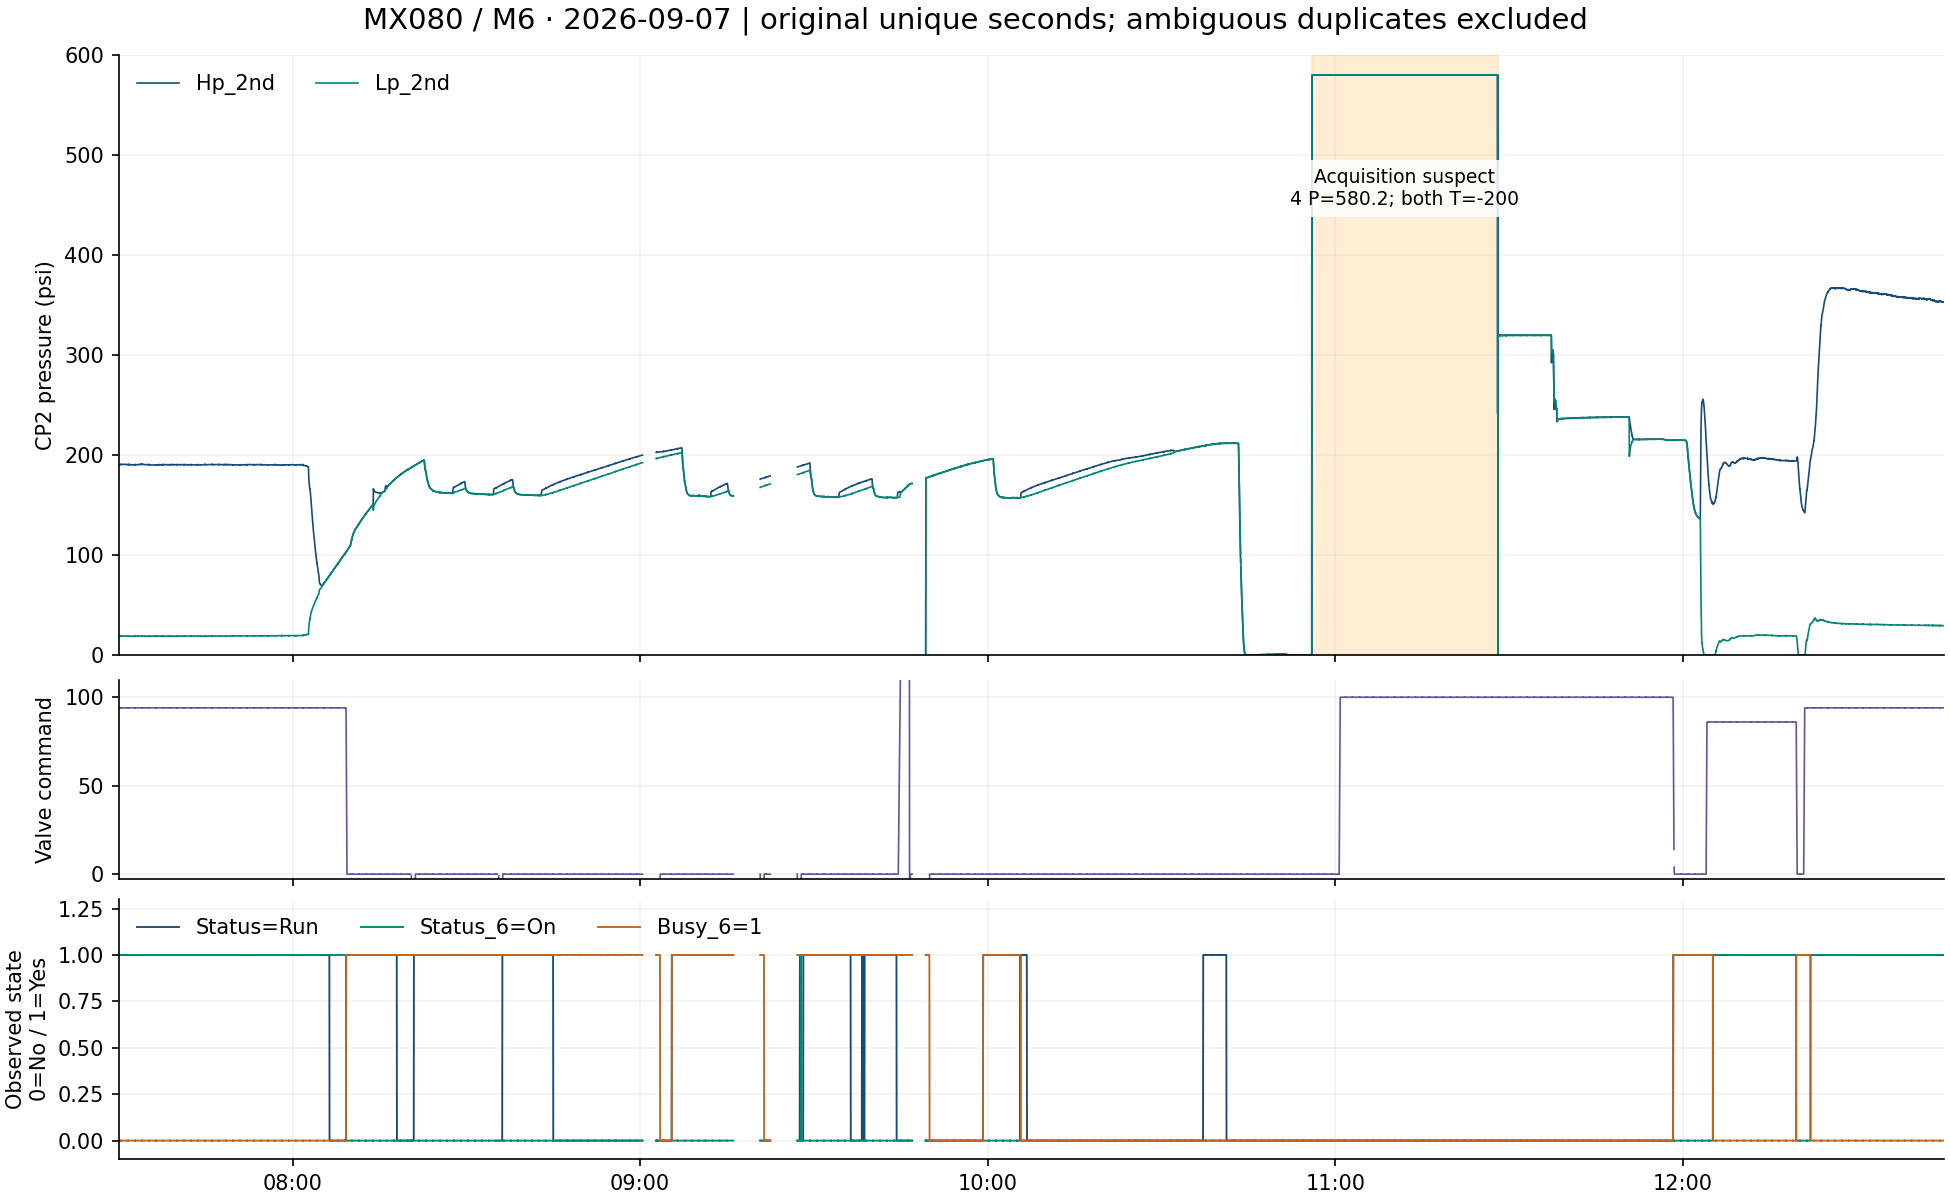

,date,rows,duplicate_occurrence_rows,hp2_max,templo_exact_minus200_seconds
0,2026-08-23,85207,0,409.8,0
1,2026-08-24,85207,0,302.1,0
2,2026-08-26,85204,0,221.0,0
3,2026-08-31,85206,0,403.7,0
4,2026-09-01,85206,0,363.6,0
5,2026-09-02,85143,6,230.0,2
6,2026-09-07,84387,130,580.2,1916
7,2026-09-08,85204,2,392.2,0
8,2026-09-10,85207,66,292.8,0
9,2026-09-12,85206,0,209.7,0


In [4]:
display(Image(filename=str(OUT/'sep7_raw_control_detail.png')))
audit=pd.DataFrame(json.loads((OUT/'raw_audit.json').read_text(encoding='utf-8')))
display(audit[['date','rows','duplicate_occurrence_rows','hp2_max','templo_exact_minus200_seconds']])

### 4. Inspect 10 September without assuming same-day recovery
Status_6=Off and Valve0 persist throughout the day. Pressure cycling/equality is real; Run→Stop20:39:15 and Stop→Run21:09:58 are observed global states. The next supported Module6 On return in the inspected history is12 Sep02:49:59, following ChangeValve. No same-day supported healthy-run claim is justified.

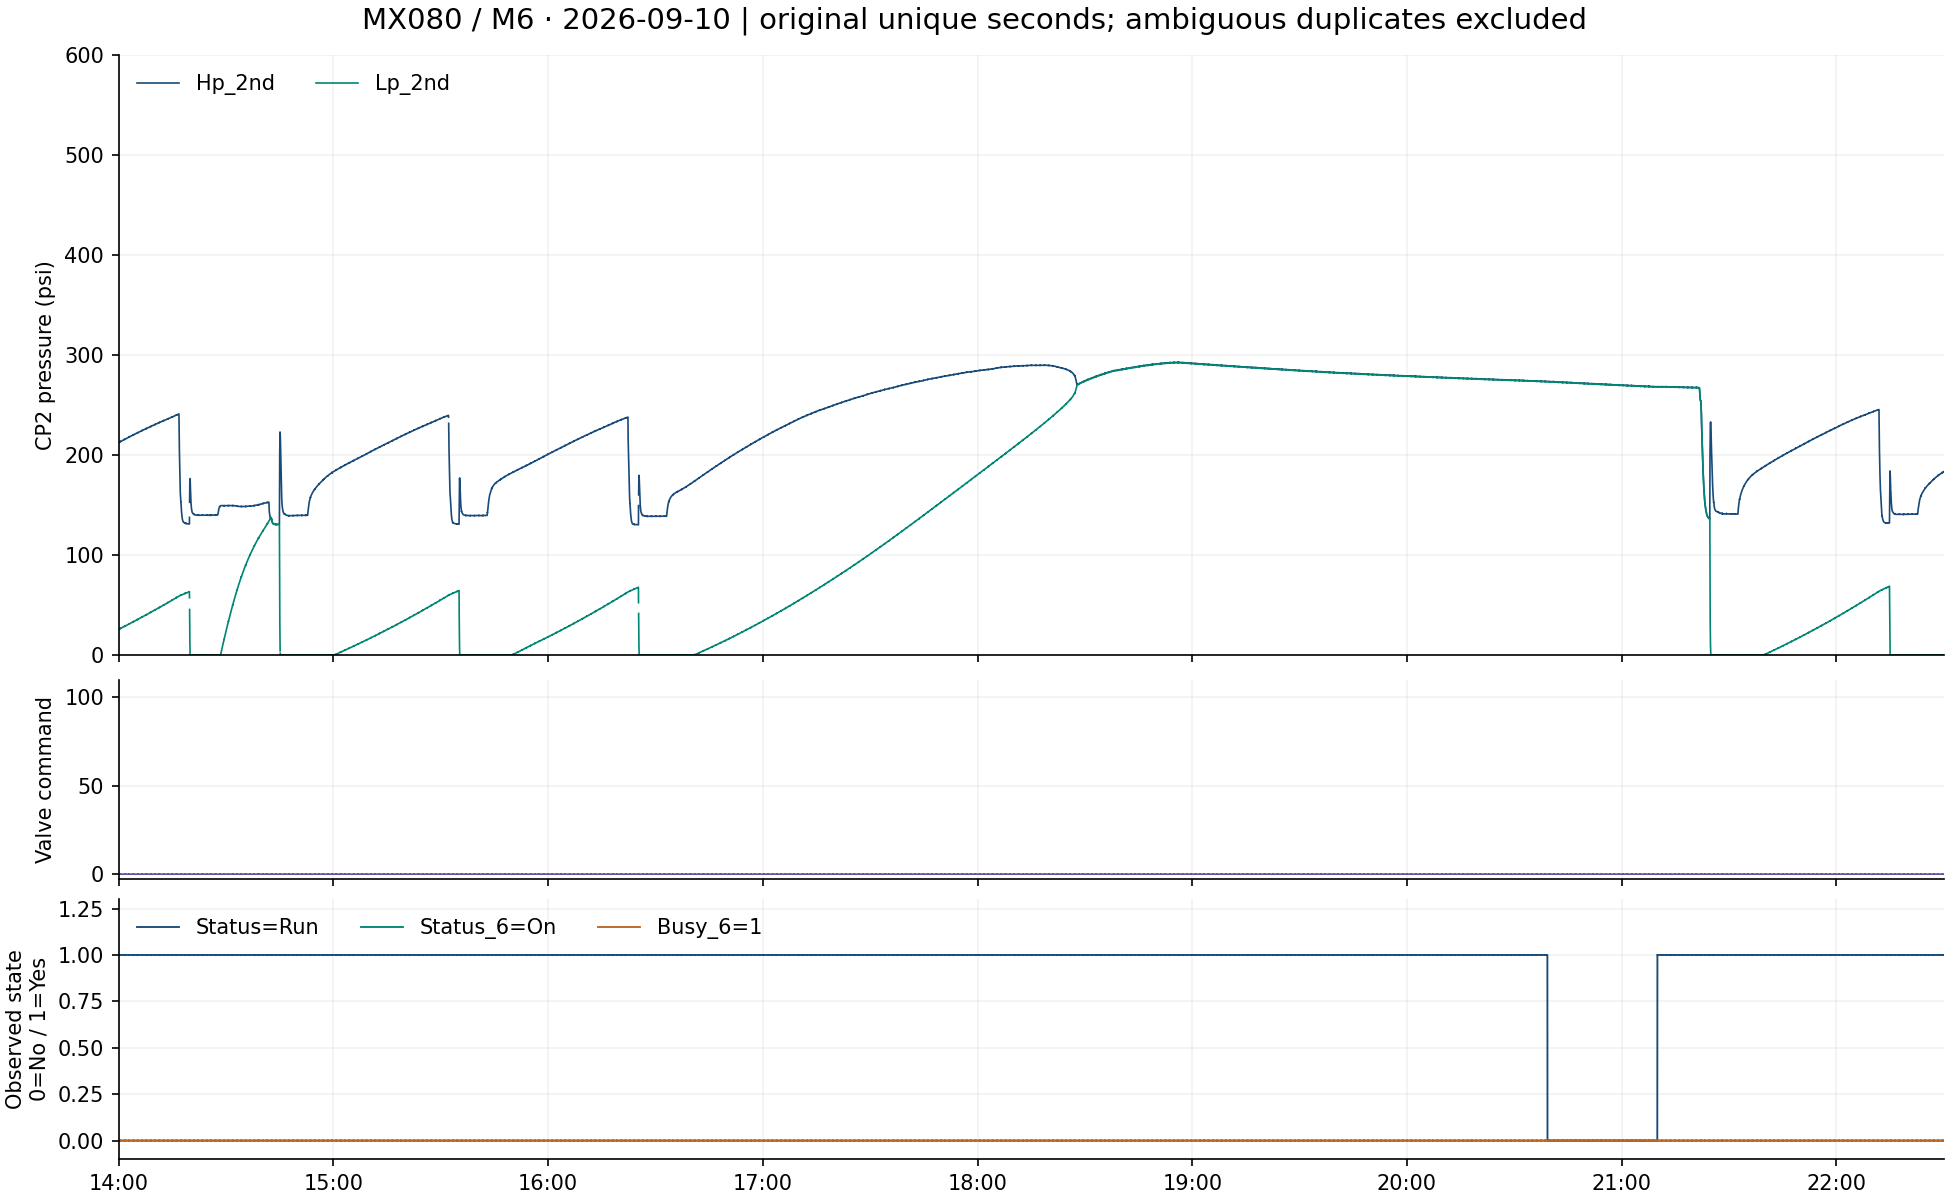

,time,before,after,gap_seconds,module,machine,event_type,witness_usable
0,2026-09-12 02:51:08,off,on,1,6,080,SV_CHANGED,True
1,2026-09-12 02:53:01,on,off,1,6,080,SV_CHANGED,True
2,2026-09-12 02:40:58,off,changevalve,1,6,080,MODULE_STATE_CHANGED,True
3,2026-09-12 02:49:59,changevalve,on,1,6,080,MODULE_STATE_CHANGED,True
4,2026-09-12 02:40:58,0,1,1,6,080,BUSY_CHANGED,True
5,2026-09-12 02:49:59,1,0,1,6,080,BUSY_CHANGED,True


In [5]:
display(Image(filename=str(OUT/'sep10_raw_control_detail.png')))
events=pd.read_parquet(OUT/'m6_observed_events.parquet')
display(events.loc[(events.time.ge('2026-09-12')) & events.event_type.ne('VALVE_CHANGED')].reset_index(drop=True))

## Checks
Source-SHA and raw count agreement:10/10 reread files. Derived Parquet checksum agreement:24/24. Independent pressure minute mean checks:30 across10days, error<1e-9. No source, model, Active pointer or event SQL writes.

In [6]:
checks=json.loads((OUT/'minute_raw_parity.json').read_text(encoding='utf-8'))
assert len(checks)==30 and max(x['max_pressure_mean_error'] for x in checks)<1e-9
print('30 sampled minute checks pass; maximum mean error:',max(x['max_pressure_mean_error'] for x in checks))

30 sampled minute checks pass; maximum mean error: 4.547473508864641e-13


## Next Steps
Keep observed control events, abnormal episodes and uncertain service hypotheses separate. Exclude unresolved intervention and confirmed abnormal periods from normal fit; assess Off/equalization separately. Review supported stable periods before donor admission; freeze a new service/config epoch when levels or Valve settings change. Shadow flags on a confirmed fault are positive detections; flag burden on reviewed normal data is evaluated separately. No supervised filling/leak labels are created from pressure shape.

## References
[Danfoss system fault diagnosis](https://www.danfoss.com/en-us/industries/food-and-beverage/dcs/cold-rooms/system-design-component-selection/application-vertical-market-sizing/troubleshooting-fault-diagnosis/) lists charge, valve, control and other differential diagnoses; application to this cascade system is a hypothesis. [Danfoss TXV troubleshooting](https://assets.danfoss.com/documents/latest/90976/AC307572949567en-010101.pdf) recommends system-wide verification and superheat/subcooling checks; current pressure/temperature tags do not provide those measurements.

Source metadata: source_receipts.json, raw_audit.json, control_event_witnesses.json. Original MessageLogs were not recovered in this task; older parsed Sep2–8 logs are secondary context only.